In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from google.colab import files
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [5]:
uploaded = files.upload()

nombre_archivo = next(iter(uploaded))

datos = pd.read_csv(
    nombre_archivo,
    skiprows=9
)

print("Tamaño del dataset:", datos.shape)
print("\nColumnas:")
print(datos.columns.tolist())

datos.head()

Saving contaminantes_2026.csv to contaminantes_2026.csv
Tamaño del dataset: (1556928, 5)

Columnas:
['date', 'id_station', 'id_parameter', 'valor', 'unit']


,date,id_station,id_parameter,valor,unit
0,2026-01-01 00:00:00,ACO,CO,NaN,15
1,2026-01-01 00:00:00,ACO,NO,NaN,1
2,2026-01-01 00:00:00,ACO,NO2,NaN,1
3,2026-01-01 00:00:00,ACO,NOX,NaN,1
4,2026-01-01 00:00:00,ACO,O3,NaN,1


In [6]:
print(datos.dtypes)

print("\nParámetros disponibles:")
print(datos['id_parameter'].value_counts())

date             object
id_station       object
id_parameter     object
valor           float64
unit              int64
dtype: object

Parámetros disponibles:
id_parameter
CO       172992
NO       172992
NO2      172992
NOX      172992
O3       172992
PM10     172992
PM2.5    172992
PMCO     172992
SO2      172992
Name: count, dtype: int64


In [7]:
datos['date_dt'] = pd.to_datetime(
    datos['date'],
    errors='coerce'
)

if 'hour' in datos.columns:

    datos['hora'] = pd.to_numeric(
        datos['hour'],
        errors='coerce'
    )

    datos['timestamp'] = (
        datos['date_dt'].dt.normalize()
        + pd.to_timedelta(datos['hora'], unit='h')
    )

else:

    datos['hora'] = datos['date_dt'].dt.hour
    datos['timestamp'] = datos['date_dt']

print("Horas detectadas:")
print(sorted(datos['hora'].dropna().unique()))

Horas detectadas:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]


# Una fila por estación-hora y una columna por contaminante

In [8]:
tabla = datos.pivot_table(
    index=['timestamp', 'id_station'],
    columns='id_parameter',
    values='valor',
    aggfunc='mean'
).reset_index()

tabla.columns.name = None

print("Dimensiones de la tabla:", tabla.shape)
print("\nColumnas:")
print(tabla.columns.tolist())

tabla.head()

Dimensiones de la tabla: (133822, 11)

Columnas:
['timestamp', 'id_station', 'CO', 'NO', 'NO2', 'NOX', 'O3', 'PM10', 'PM2.5', 'PMCO', 'SO2']


,timestamp,id_station,CO,NO,NO2,NOX,O3,PM10,PM2.5,PMCO,SO2
0,2026-01-01,AJM,0.74,2.0,26.0,28.0,19.0,67.0,53.0,14.0,28.0
1,2026-01-01,ATI,0.70,2.0,21.0,23.0,18.0,90.0,NaN,NaN,22.0
2,2026-01-01,BJU,1.07,NaN,32.0,NaN,17.0,62.0,41.0,21.0,3.0
3,2026-01-01,CAM,NaN,7.0,44.0,52.0,4.0,57.0,49.0,8.0,25.0
4,2026-01-01,CCA,1.12,1.0,32.0,33.0,13.0,NaN,27.0,NaN,3.0


In [9]:
faltantes = tabla.isna().sum()

print("Valores faltantes por columna:")
print(faltantes)

Valores faltantes por columna:
timestamp         0
id_station        0
CO            22725
NO            34655
NO2           23703
NOX           34654
O3             9352
PM10          57621
PM2.5         75093
PMCO          97651
SO2           30776
dtype: int64


# Covarianza y correlación de CO con NOX

In [10]:
co_nox = tabla[
    ['CO', 'NOX']
].dropna()

print("Observaciones utilizadas:", len(co_nox))

Observaciones utilizadas: 92392


In [11]:
cov_co_nox = co_nox['CO'].cov(co_nox['NOX'])

corr_co_nox = co_nox['CO'].corr(co_nox['NOX'])

print(f"Covarianza CO-NOX: {cov_co_nox:.4f}")
print(f"Correlación CO-NOX: {corr_co_nox:.4f}")

Covarianza CO-NOX: 11.5867
Correlación CO-NOX: 0.8656


La covarianza y la correlación describen la relación entre dos variables, pero no representan exactamente lo mismo. La covarianza depende de las unidades y de la escala de las variables, mientras que la correlación estandariza esta relación y siempre toma valores entre -1 y 1. Por esta razón, sus valores numéricos son diferentes aunque ambas indiquen la dirección de la asociación entre CO y NOX.

# Eigenvalores de la matriz de correlación

In [12]:
contaminantes = [
    'CO',
    'NO',
    'NO2',
    'NOX',
    'O3',
    'PM10',
    'PM2.5',
    'PMCO',
    'SO2'
]

contaminantes = [
    x for x in contaminantes
    if x in tabla.columns
]

print(contaminantes)

['CO', 'NO', 'NO2', 'NOX', 'O3', 'PM10', 'PM2.5', 'PMCO', 'SO2']


In [13]:
corr_con_faltantes = tabla[
    contaminantes
].corr()

corr_con_faltantes

,CO,NO,NO2,NOX,O3,PM10,PM2.5,PMCO,SO2
CO,1.000000,0.754645,0.769117,0.865630,-0.338433,0.421650,0.400146,0.414038,0.158971
NO,0.754645,1.000000,0.483864,0.938831,-0.384038,0.259735,0.192164,0.293456,0.091705
NO2,0.769117,0.483864,1.000000,0.755364,-0.434339,0.399426,0.338749,0.411946,0.160842
NOX,0.865630,0.938831,0.755364,1.000000,-0.453609,0.352691,0.283656,0.378046,0.128637
O3,-0.338433,-0.384038,-0.434339,-0.453609,1.000000,0.077362,0.182075,0.037393,-0.036383
PM10,0.421650,0.259735,0.399426,0.352691,0.077362,1.000000,0.845858,0.840878,0.229808
PM2.5,0.400146,0.192164,0.338749,0.283656,0.182075,0.845858,1.000000,0.437513,0.237217
PMCO,0.414038,0.293456,0.411946,0.378046,0.037393,0.840878,0.437513,1.000000,0.236809
SO2,0.158971,0.091705,0.160842,0.128637,-0.036383,0.229808,0.237217,0.236809,1.000000


In [14]:
eigen_con_faltantes = np.linalg.eigvalsh(
    corr_con_faltantes.values
)

eigen_con_faltantes = np.sort(
    eigen_con_faltantes
)[::-1]

print("Eigenvalores usando correlaciones con datos faltantes:")
print(eigen_con_faltantes)

Eigenvalores usando correlaciones con datos faltantes:
[ 4.30334433e+00  1.99286324e+00  9.18607074e-01  6.57686418e-01
  5.58406495e-01  4.28956904e-01  1.43673157e-01  7.40368316e-05
 -3.61164851e-03]


In [15]:
tabla_completa = tabla[
    contaminantes
].dropna()

print("Filas originales:", len(tabla))
print("Filas sin ningún faltante:", len(tabla_completa))

Filas originales: 133822
Filas sin ningún faltante: 17955


In [16]:
corr_sin_faltantes = tabla_completa.corr()

corr_sin_faltantes

,CO,NO,NO2,NOX,O3,PM10,PM2.5,PMCO,SO2
CO,1.000000,0.760368,0.812196,0.882208,-0.337289,0.481884,0.397173,0.414364,0.170822
NO,0.760368,1.000000,0.527801,0.935694,-0.383128,0.292096,0.185356,0.310939,0.142370
NO2,0.812196,0.527801,1.000000,0.793262,-0.425752,0.492386,0.391937,0.438653,0.196326
NOX,0.882208,0.935694,0.793262,1.000000,-0.451323,0.413763,0.295555,0.404968,0.183459
O3,-0.337289,-0.383128,-0.425752,-0.451323,1.000000,0.155989,0.241364,0.011829,-0.068702
PM10,0.481884,0.292096,0.492386,0.413763,0.155989,1.000000,0.854269,0.827192,0.282470
PM2.5,0.397173,0.185356,0.391937,0.295555,0.241364,0.854269,1.000000,0.415457,0.258724
PMCO,0.414364,0.310939,0.438653,0.404968,0.011829,0.827192,0.415457,1.000000,0.215682
SO2,0.170822,0.142370,0.196326,0.183459,-0.068702,0.282470,0.258724,0.215682,1.000000


In [17]:
eigen_sin_faltantes = np.linalg.eigvalsh(
    corr_sin_faltantes.values
)

eigen_sin_faltantes = np.sort(
    eigen_sin_faltantes
)[::-1]

print("Eigenvalores sin faltantes:")
print(eigen_sin_faltantes)

Eigenvalores sin faltantes:
[4.45566736e+00 1.97826856e+00 9.12215561e-01 6.44520919e-01
 5.52580044e-01 3.34202907e-01 1.22035593e-01 3.77960257e-04
 1.31095637e-04]


In [18]:
comparacion_eigen = pd.DataFrame({
    'Con faltantes': eigen_con_faltantes,
    'Sin faltantes': eigen_sin_faltantes
})

comparacion_eigen

,Con faltantes,Sin faltantes
0,4.303344,4.455667
1,1.992863,1.978269
2,0.918607,0.912216
3,0.657686,0.644521
4,0.558406,0.552580
5,0.428957,0.334203
6,0.143673,0.122036
7,0.000074,0.000378
8,-0.003612,0.000131


# Predecir PM2.5 usando los demás contaminantes

In [19]:
objetivo = 'PM2.5'

predictores_todos = [
    x for x in contaminantes
    if x != objetivo
]

print("Objetivo:")
print(objetivo)

print("\nPredictores:")
print(predictores_todos)

Objetivo:
PM2.5

Predictores:
['CO', 'NO', 'NO2', 'NOX', 'O3', 'PM10', 'PMCO', 'SO2']


In [20]:
modelo_todos_df = tabla[
    [objetivo] + predictores_todos
].dropna()

print("Observaciones utilizadas:", len(modelo_todos_df))

Observaciones utilizadas: 17955


In [21]:
X_todos = modelo_todos_df[
    predictores_todos
]

y_todos = modelo_todos_df[
    objetivo
]

X_todos_const = sm.add_constant(X_todos)

modelo_todos = sm.OLS(
    y_todos,
    X_todos_const
).fit()

print(modelo_todos.summary())

                            OLS Regression Results                            
Dep. Variable:                  PM2.5   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 1.325e+06
Date:                Sat, 03 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:32:02   Log-Likelihood:                -13038.
No. Observations:               17955   AIC:                         2.609e+04
Df Residuals:                   17946   BIC:                         2.616e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0074      0.011      0.649      0.5

In [22]:
print(
    f"R² usando todos los contaminantes: "
    f"{modelo_todos.rsquared:.4f}"
)

R² usando todos los contaminantes: 0.9983


In [ ]:
vif_todos = pd.DataFrame()

vif_todos['Variable'] = X_todos.columns

vif_todos['VIF'] = [
    variance_inflation_factor(
        X_todos.values,
        i
    )
    for i in range(X_todos.shape[1])
]

vif_todos

# Solamente gases

In [23]:
gases = [
    'CO',
    'NO',
    'NO2',
    'NOX',
    'O3',
    'SO2'
]

gases = [
    x for x in gases
    if x in tabla.columns
]

print("Gases utilizados:")
print(gases)

Gases utilizados:
['CO', 'NO', 'NO2', 'NOX', 'O3', 'SO2']


In [24]:
modelo_gases_df = tabla[
    ['PM2.5'] + gases
].dropna()

print(
    "Observaciones disponibles:",
    len(modelo_gases_df)
)

Observaciones disponibles: 32686


In [25]:
X_gases = modelo_gases_df[gases]

y_gases = modelo_gases_df['PM2.5']

X_gases_const = sm.add_constant(
    X_gases
)

modelo_gases = sm.OLS(
    y_gases,
    X_gases_const
).fit()

print(modelo_gases.summary())

                            OLS Regression Results                            
Dep. Variable:                  PM2.5   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.317
Method:                 Least Squares   F-statistic:                     2524.
Date:                Sat, 03 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:33:07   Log-Likelihood:            -1.2420e+05
No. Observations:               32686   AIC:                         2.484e+05
Df Residuals:                   32679   BIC:                         2.485e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5865      0.184      8.629      0.0

In [26]:
print(
    f"R² usando solamente gases: "
    f"{modelo_gases.rsquared:.4f}"
)

R² usando solamente gases: 0.3167


In [27]:
vif_gases = pd.DataFrame()

vif_gases['Variable'] = gases

vif_gases['VIF'] = [
    variance_inflation_factor(
        X_gases.values,
        i
    )
    for i in range(len(gases))
]

vif_gases

,Variable,VIF
0,CO,4.230546
1,NO,2343.290268
2,NO2,680.407946
3,NOX,4233.452205
4,O3,1.339026
5,SO2,1.039904


In [28]:
comparacion_modelos = pd.DataFrame({
    'Modelo': [
        'Todos los contaminantes',
        'Solo gases'
    ],
    'R2': [
        modelo_todos.rsquared,
        modelo_gases.rsquared
    ],
    'n': [
        len(modelo_todos_df),
        len(modelo_gases_df)
    ]
})

comparacion_modelos

,Modelo,R2,n
0,Todos los contaminantes,0.998310,17955
1,Solo gases,0.316695,32686


# Matriz H

In [32]:
# Variables que necesitamos para este análisis
variables_h = [
    'PM2.5',
    'CO',
    'NO',
    'NO2',
    'NOX',
    'O3',
    'SO2'
]

# Nos quedamos solo con filas completas
base_h = tabla[
    ['timestamp', 'id_station'] + variables_h
].dropna(subset=variables_h).copy()

print("Filas completas disponibles:", len(base_h))
print("Estaciones disponibles:", base_h['id_station'].nunique())

Filas completas disponibles: 32686
Estaciones disponibles: 11


In [33]:
# Identificar la semana correspondiente a cada observación
base_h['semana'] = (
    base_h['timestamp']
    .dt.to_period('W')
)

base_h.head()

,timestamp,id_station,PM2.5,CO,NO,NO2,NOX,O3,SO2,semana
0,2026-01-01,AJM,53.0,0.74,2.0,26.0,28.0,19.0,28.0,2025-12-29/2026-01-04
4,2026-01-01,CCA,27.0,1.12,1.0,32.0,33.0,13.0,3.0,2025-12-29/2026-01-04
15,2026-01-01,NEZ,56.0,1.80,19.0,51.0,70.0,6.0,9.0,2025-12-29/2026-01-04
16,2026-01-01,PED,45.0,1.06,5.0,40.0,45.0,4.0,8.0,2025-12-29/2026-01-04
17,2026-01-01,SAC,67.0,2.35,42.0,49.0,91.0,5.0,5.0,2025-12-29/2026-01-04


In [34]:
conteo_semanas = (
    base_h
    .groupby(['id_station', 'semana'])
    .size()
    .sort_values(ascending=False)
)

print("Estaciones y semanas con más datos completos:")
display(conteo_semanas.head(15))

Estaciones y semanas con más datos completos:


id_station  semana               
CAM         2026-04-06/2026-04-12    168
SAC         2026-07-20/2026-07-26    168
PED         2026-02-09/2026-02-15    168
SAC         2026-07-13/2026-07-19    168
CCA         2026-03-09/2026-03-15    165
            2026-01-05/2026-01-11    165
            2026-03-23/2026-03-29    165
MER         2026-02-02/2026-02-08    165
MON         2026-03-23/2026-03-29    165
NEZ         2026-01-19/2026-01-25    165
            2026-03-09/2026-03-15    165
MER         2026-04-27/2026-05-03    165
            2026-03-09/2026-03-15    165
SAC         2026-01-05/2026-01-11    165
PED         2026-01-05/2026-01-11    165
dtype: int64

In [35]:
if len(conteo_semanas) == 0:
    raise ValueError(
        "No existen combinaciones estación-semana con todas las variables completas."
    )

mejor_estacion, mejor_semana = conteo_semanas.index[0]

print("Estación seleccionada:", mejor_estacion)
print("Semana seleccionada:", mejor_semana)
print("Observaciones:", conteo_semanas.iloc[0])

Estación seleccionada: CAM
Semana seleccionada: 2026-04-06/2026-04-12
Observaciones: 168


In [36]:
semana = base_h[
    (base_h['id_station'] == mejor_estacion) &
    (base_h['semana'] == mejor_semana)
].copy()

semana = semana.sort_values('timestamp')

print("Estación:", mejor_estacion)
print("Semana:", mejor_semana)
print("Número de observaciones:", len(semana))

semana.head()

Estación: CAM
Semana: 2026-04-06/2026-04-12
Número de observaciones: 168


,timestamp,id_station,PM2.5,CO,NO,NO2,NOX,O3,SO2,semana
57119,2026-04-06 00:00:00,CAM,2.0,0.07,1.0,13.0,13.0,20.0,4.0,2026-04-06/2026-04-12
57141,2026-04-06 01:00:00,CAM,11.0,0.06,0.0,7.0,7.0,28.0,8.0,2026-04-06/2026-04-12
57161,2026-04-06 02:00:00,CAM,8.0,0.02,0.0,8.0,8.0,23.0,1.0,2026-04-06/2026-04-12
57181,2026-04-06 03:00:00,CAM,9.0,0.08,1.0,14.0,14.0,18.0,1.0,2026-04-06/2026-04-12
57208,2026-04-06 04:00:00,CAM,4.0,0.13,1.0,21.0,23.0,13.0,1.0,2026-04-06/2026-04-12


In [37]:
predictores_h = [
    'CO',
    'NO',
    'NO2',
    'O3',
    'SO2'
]

X_semana = semana[predictores_h].to_numpy()

# Agregar intercepto
X_semana = np.column_stack([
    np.ones(len(X_semana)),
    X_semana
])

n, p = X_semana.shape

print("Número de observaciones n:", n)
print("Número de parámetros p:", p)

print("Rango de X:", np.linalg.matrix_rank(X_semana))

Número de observaciones n: 168
Número de parámetros p: 6
Rango de X: 6


In [38]:
XtX_inv = np.linalg.inv(
    X_semana.T @ X_semana
)

H = (
    X_semana
    @ XtX_inv
    @ X_semana.T
)

print("Dimensión de H:", H.shape)

Dimensión de H: (168, 168)


In [39]:
H2 = H @ H

print(
    "¿H² = H?",
    np.allclose(H2, H, atol=1e-8)
)

print(
    "Diferencia máxima:",
    np.max(np.abs(H2 - H))
)

¿H² = H? True
Diferencia máxima: 2.4424906541753444e-15


In [40]:
traza_H = np.trace(H)

print("Traza de H:", traza_H)
print("p:", p)

print(
    "¿traza(H) = p?",
    np.isclose(traza_H, p)
)

Traza de H: 5.999999999999985
p: 6
¿traza(H) = p? True


Para la estación y semana seleccionadas se construyó la matriz hat H, con dimensión 168 X 168. Se verificó numéricamente que H^2=H, con una diferencia máxima del orden de 10^(-15), por lo que H es idempotente. También se obtuvo una traza de aproximadamente 6, igual al número de parámetros p=6, confirmando la propiedad tr(H)=p

In [41]:
# Datos completos para calcular leverage en todas las observaciones

datos_lev = tabla[
    ['timestamp', 'id_station', 'PM2.5'] + predictores_h
].dropna().copy()

datos_lev = datos_lev.reset_index(drop=True)

print("Número total de observaciones:", len(datos_lev))

datos_lev.head()

Número total de observaciones: 32687


,timestamp,id_station,PM2.5,CO,NO,NO2,O3,SO2
0,2026-01-01,AJM,53.0,0.74,2.0,26.0,19.0,28.0
1,2026-01-01,CCA,27.0,1.12,1.0,32.0,13.0,3.0
2,2026-01-01,NEZ,56.0,1.80,19.0,51.0,6.0,9.0
3,2026-01-01,PED,45.0,1.06,5.0,40.0,4.0,8.0
4,2026-01-01,SAC,67.0,2.35,42.0,49.0,5.0,5.0


In [42]:
# Matriz de predictores
X_all = datos_lev[predictores_h].to_numpy()

# Agregar intercepto
X_all = np.column_stack([
    np.ones(len(X_all)),
    X_all
])

n_all, p_all = X_all.shape

print("n =", n_all)
print("p =", p_all)

n = 32687
p = 6


In [43]:
# Calcular (X'X)^-1
XtX_inv_all = np.linalg.inv(
    X_all.T @ X_all
)

# Calcular solo la diagonal de H
# SIN construir la matriz H completa
leverage = np.einsum(
    'ij,jk,ik->i',
    X_all,
    XtX_inv_all,
    X_all
)

datos_lev['leverage'] = leverage

datos_lev[
    ['timestamp', 'id_station', 'leverage']
].head()

,timestamp,id_station,leverage
0,2026-01-01,AJM,0.000809
1,2026-01-01,CCA,0.000318
2,2026-01-01,NEZ,0.000685
3,2026-01-01,PED,0.000226
4,2026-01-01,SAC,0.001312


In [44]:
print("Suma de leverages:", datos_lev['leverage'].sum())
print("p:", p_all)

print(
    "¿Suma de leverages = p?",
    np.isclose(
        datos_lev['leverage'].sum(),
        p_all
    )
)

Suma de leverages: 5.9999999999999964
p: 6
¿Suma de leverages = p? True


In [45]:
top10_leverage = (
    datos_lev
    .sort_values(
        'leverage',
        ascending=False
    )
    .head(10)
)

display(
    top10_leverage[
        [
            'timestamp',
            'id_station',
            'PM2.5',
            'leverage'
        ]
    ]
)

,timestamp,id_station,PM2.5,leverage
1291,2026-01-08 05:00:00,UAX,25.0,0.018059
1664,2026-01-10 07:00:00,UAX,39.0,0.011275
2157,2026-01-13 01:00:00,TLA,21.0,0.010669
7227,2026-02-18 07:00:00,MER,37.0,0.010448
5542,2026-02-05 20:00:00,CCA,34.0,0.010301
6401,2026-02-12 03:00:00,UIZ,40.0,0.008584
6398,2026-02-12 03:00:00,MER,28.0,0.008299
6412,2026-02-12 05:00:00,UAX,31.0,0.008033
13019,2026-03-27 05:00:00,UAX,18.0,0.007373
5726,2026-02-07 07:00:00,UAX,26.0,0.007150


In [46]:
umbral_leverage = 2 * p_all / n_all

print(
    f"Umbral aproximado de leverage alto: "
    f"{umbral_leverage:.6f}"
)

print(
    "Observaciones por encima del umbral:",
    (datos_lev['leverage'] > umbral_leverage).sum()
)

Umbral aproximado de leverage alto: 0.000367
Observaciones por encima del umbral: 2521


In [47]:
datos_lev[
    datos_lev['leverage'] > umbral_leverage
][
    ['timestamp', 'id_station', 'leverage']
].sort_values(
    'leverage',
    ascending=False
).head(20)

,timestamp,id_station,leverage
1291,2026-01-08 05:00:00,UAX,0.018059
1664,2026-01-10 07:00:00,UAX,0.011275
2157,2026-01-13 01:00:00,TLA,0.010669
7227,2026-02-18 07:00:00,MER,0.010448
5542,2026-02-05 20:00:00,CCA,0.010301
6401,2026-02-12 03:00:00,UIZ,0.008584
6398,2026-02-12 03:00:00,MER,0.008299
6412,2026-02-12 05:00:00,UAX,0.008033
13019,2026-03-27 05:00:00,UAX,0.007373
5726,2026-02-07 07:00:00,UAX,0.007150


Para todas las observaciones se calculó el leverage sin construir explícitamente la matriz H completa. Se utilizó la expresión que permite obtener directamente los elementos diagonales de H. Como comprobación, la suma de todos los valores de leverage fue aproximadamente igual a p=6, consistente con la propiedad tr(H)=p.

# Cook's Distance

In [48]:
y_all = datos_lev['PM2.5'].to_numpy()

modelo_cook = sm.OLS(
    y_all,
    X_all
).fit()

print(modelo_cook.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.317
Method:                 Least Squares   F-statistic:                     3029.
Date:                Sat, 03 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:47:37   Log-Likelihood:            -1.2420e+05
No. Observations:               32687   AIC:                         2.484e+05
Df Residuals:                   32681   BIC:                         2.485e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5885      0.184      8.642      0.0

In [49]:
influencia = modelo_cook.get_influence()

cook_distance = influencia.cooks_distance[0]

datos_lev['cook_distance'] = cook_distance

datos_lev[
    [
        'timestamp',
        'id_station',
        'leverage',
        'cook_distance'
    ]
].head()

,timestamp,id_station,leverage,cook_distance
0,2026-01-01,AJM,0.000809,6.237366e-04
1,2026-01-01,CCA,0.000318,6.661327e-07
2,2026-01-01,NEZ,0.000685,2.823308e-04
3,2026-01-01,PED,0.000226,1.006445e-04
4,2026-01-01,SAC,0.001312,1.102715e-03


In [50]:
top10_cook = (
    datos_lev
    .sort_values(
        'cook_distance',
        ascending=False
    )
    .head(10)
)

display(
    top10_cook[
        [
            'timestamp',
            'id_station',
            'PM2.5',
            'leverage',
            'cook_distance'
        ]
    ]
)

,timestamp,id_station,PM2.5,leverage,cook_distance
55,2026-01-01 07:00:00,SAC,323.0,0.002604,0.295453
25,2026-01-01 03:00:00,SAC,349.0,0.002228,0.295351
62,2026-01-01 08:00:00,SAC,296.0,0.002589,0.226659
18,2026-01-01 02:00:00,SAC,324.0,0.001767,0.198626
32,2026-01-01 04:00:00,SAC,290.0,0.001582,0.143248
37,2026-01-01 05:00:00,NEZ,255.0,0.001713,0.112115
47,2026-01-01 06:00:00,SAC,182.0,0.003606,0.093436
69,2026-01-01 09:00:00,SAC,305.0,0.000906,0.086581
45,2026-01-01 06:00:00,NEZ,289.0,0.000845,0.080418
11,2026-01-01 01:00:00,SAC,201.0,0.002086,0.071208


In [51]:
indices_lev = set(
    top10_leverage.index
)

indices_cook = set(
    top10_cook.index
)

coinciden = indices_lev.intersection(
    indices_cook
)

print(
    "Número de observaciones que aparecen en ambos Top 10:",
    len(coinciden)
)

print(
    "¿Los Top 10 son exactamente iguales?",
    indices_lev == indices_cook
)

Número de observaciones que aparecen en ambos Top 10: 0
¿Los Top 10 son exactamente iguales? False


In [53]:
leverage_statsmodels = influencia.hat_matrix_diag

print(
    "¿Nuestro leverage coincide con statsmodels?",
    np.allclose(
        datos_lev['leverage'],
        leverage_statsmodels
    )
)

print(
    "Diferencia máxima:",
    np.max(
        np.abs(
            datos_lev['leverage']
            - leverage_statsmodels
        )
    )
)

¿Nuestro leverage coincide con statsmodels? True
Diferencia máxima: 7.806255641895632e-17


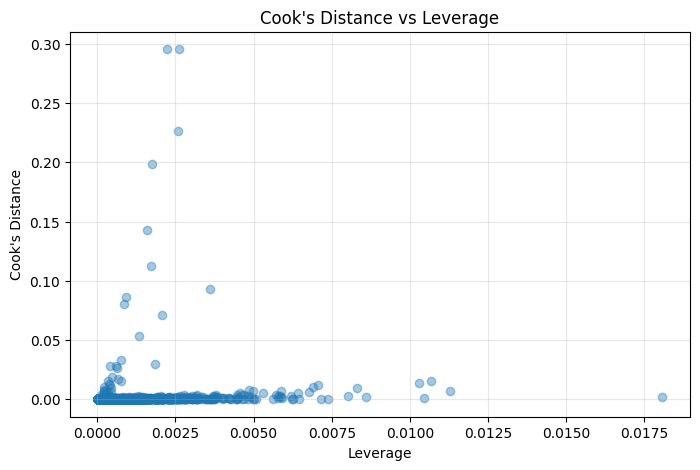

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(
    datos_lev['leverage'],
    datos_lev['cook_distance'],
    alpha=0.4
)

plt.xlabel('Leverage')
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance vs Leverage")

plt.grid(alpha=0.3)

plt.show()

In [55]:
print("Coincidencias:", len(coinciden))
print("¿Son exactamente los mismos?", indices_lev == indices_cook)

Coincidencias: 0
¿Son exactamente los mismos? False


Los 10 puntos más influyentes según Cook’s Distance no coinciden con los 10 puntos de mayor leverage; de hecho, no hubo ninguna coincidencia entre ambos grupos. Esto muestra que un leverage alto no implica necesariamente una alta influencia sobre el modelo. El leverage mide qué tan extrema es una observación respecto a las variables predictoras, mientras que Cook’s Distance considera además el tamaño del residuo. Por esta razón, una observación puede tener un leverage alto pero una influencia pequeña si el modelo la ajusta bien, y también puede tener un leverage moderado pero una Cook’s Distance alta si su residuo es grande.